In [8]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set Tampilan Grafik
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("=== TAHAP 0: AUDIT RINCIAN DATAFRAME DARI TIAP FILE EXCEL ===")

# 1. Definisi Direktori Path Khusus
DATA_DIR = r"C:\Users\azwar kurnia\Documents\Tugas Kuliah Sains Data\Semester 5\Data Warehouse\Data_Tugas"

# 2. Ambil seluruh file Excel (.xlsx) di direktori target
excel_files = sorted(glob.glob(os.path.join(DATA_DIR, "*.xlsx")))

print(f"Direktori Target : {DATA_DIR}")
print(f"Total File Excel : {len(excel_files)} file\n")

# 3. Iterasi dan tampilkan ringkasan struktur tiap file Excel
audit_results = []

for idx, file_path in enumerate(excel_files, 1):
    file_name = os.path.basename(file_path)
    xls = pd.ExcelFile(file_path)
    
    for sheet in xls.sheet_names:
        df_temp = pd.read_excel(file_path, sheet_name=sheet)
        rows, cols = df_temp.shape
        null_count = df_temp.isnull().sum().sum()
        
        # Cek status data
        if rows == 0 and cols == 0:
            status = "KOSONG TOTAL (0x0)"
        elif rows == 0:
            status = "KOSONG (0 Baris)"
        else:
            status = "TERISI"
            
        audit_results.append({
            'No': idx,
            'Nama File': file_name,
            'Sheet': sheet,
            'Dimensi (Baris x Kolom)': f"{rows} x {cols}",
            'Total Missing Values': null_count,
            'Status Data': status
        })

# Tampilkan tabel audit
audit_df = pd.DataFrame(audit_results)
display(audit_df)

=== TAHAP 0: AUDIT RINCIAN DATAFRAME DARI TIAP FILE EXCEL ===
Direktori Target : C:\Users\azwar kurnia\Documents\Tugas Kuliah Sains Data\Semester 5\Data Warehouse\Data_Tugas
Total File Excel : 9 file



,No,Nama File,Sheet,Dimensi (Baris x Kolom),Total Missing Values,Status Data
0,1,AUDIT SISTEM INFORMASI AKADEMIK (SIAKAD) (Res...,Form Responses 1,22 x 25,8.0,TERISI
1,2,AUDIT SISTEM SIAKAD UINRIL KELOMPOK 6.xlsx,Sheet1,0 x 0,0.0,KOSONG TOTAL (0x0)
2,2,AUDIT SISTEM SIAKAD UINRIL KELOMPOK 6.xlsx,Form Responses 1,21 x 25,0.0,TERISI
3,3,AUDIT SISTEM SIAKAD UINRIL (Jawaban).xlsx,Form Responses 1,24 x 25,1.0,TERISI
4,4,Formulir tanpa judul (Jawaban).xlsx,Form Responses 1,31 x 21,21.0,TERISI
5,5,Kuesioner Audit Sistem Informasi Akademik (SIA...,Form Responses 1,20 x 24,0.0,TERISI
6,6,Kuesioner Evaluasi Pengalaman Pengguna SIAKAD ...,Form Responses 1,24 x 27,24.0,TERISI
7,7,Kuesioner Sistem Informasi Akademik (Jawaban)....,Form Responses 1,30 x 24,0.0,TERISI
8,8,Untitled form (Responses).xlsx,Form Responses 1,27 x 23,0.0,TERISI
9,9,responden kl 9.xlsx,Form Responses 1,25 x 22,0.0,TERISI


In [9]:
print("=== TAHAP 1: DATA WAREHOUSE (PENGUMPULAN DATA TERPUSAT) ===")

list_dataframe = []

for file_path in excel_files:
    file_name = os.path.basename(file_path)
    xls = pd.ExcelFile(file_path)
    
    for sheet in xls.sheet_names:
        # LEWATKAN SHEET KOSONG (Hasil Temuan Tahap 0)
        if sheet == 'Sheet1' and 'KELOMPOK 6' in file_name:
            print(f"Skipping Sheet Kosong: File '{file_name}' -> Sheet '{sheet}'")
            continue
            
        df_temp = pd.read_excel(file_path, sheet_name=sheet)
        if not df_temp.empty and df_temp.shape[0] > 0:
            df_temp['Source_File'] = file_name  # Catat nama file asal
            list_dataframe.append(df_temp)

# Tumpuk semua dataframe menjadi satu Master Dataframe awal
raw_master_df = pd.concat(list_dataframe, ignore_index=True)

print("\nProses penggabungan data terpusat selesai.")
print(f"Jumlah total baris terkumpul : {len(raw_master_df)} baris responden")
print(f"Jumlah total kolom awal     : {raw_master_df.shape[1]} kolom")

=== TAHAP 1: DATA WAREHOUSE (PENGUMPULAN DATA TERPUSAT) ===
Skipping Sheet Kosong: File 'AUDIT SISTEM SIAKAD UINRIL  KELOMPOK 6.xlsx' -> Sheet 'Sheet1'

Proses penggabungan data terpusat selesai.
Jumlah total baris terkumpul : 224 baris responden
Jumlah total kolom awal     : 130 kolom


In [10]:
print("=== TAHAP 2: PRE-PROCESSING DATA ===")

# 1. Kamus Konversi Teks Likert ke Angka Kuantitatif
likert_mapping = {
    'Sangat Setuju': 5, 'SS': 5, 'Sangat Baik': 5, 'Sangat Puas': 5, '5': 5, 5: 5, 5.0: 5,
    'Setuju': 4, 'S': 4, 'Baik': 4, 'Puas': 4, '4': 4, 4: 4, 4.0: 4,
    'Ragu-ragu': 3, 'Netral': 3, 'Cukup': 3, 'N': 3, 'Cukup Puas': 3, '3': 3, 3: 3, 3.0: 3,
    'Tidak Setuju': 2, 'TS': 2, 'Buruk': 2, 'Tidak Puas': 2, '2': 2, 2: 2, 2.0: 2,
    'Sangat Tidak Setuju': 1, 'STS': 1, 'Sangat Buruk': 1, 'Sangat Tidak Puas': 1, '1': 1, 1: 1, 1.0: 1
}

clean_df = raw_master_df.copy()

def convert_value_to_likert(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip()
    return likert_mapping.get(val_str, likert_mapping.get(val, np.nan))

# Imputasi sel kosong
for col in clean_df.columns:
    if col not in ['Timestamp', 'Source_File', 'Nama', 'NPM', 'Prodi', 'Fakultas', 'Semester']:
        converted_series = clean_df[col].apply(convert_value_to_likert)
        if converted_series.notna().sum() > 0:
            clean_df[col] = converted_series
            # Imputasi Median untuk Kuantitatif
            col_median = clean_df[col].median()
            clean_df[col] = clean_df[col].fillna(col_median if pd.notna(col_median) else 3)
        else:
            # Imputasi Teks untuk Kualitatif
            clean_df[col] = clean_df[col].fillna('Tidak Memberikan Tanggapan')

print("Proses Pre-processing selesai.")
print("Seluruh variabel kuantitatif terkonversi ke angka 1.0 - 5.0 tanpa missing values.")

=== TAHAP 2: PRE-PROCESSING DATA ===
Proses Pre-processing selesai.
Seluruh variabel kuantitatif terkonversi ke angka 1.0 - 5.0 tanpa missing values.


In [11]:
print("=== TAHAP 3: STANDARISASI DATA ===")

# 1. Kamus Acuan Fakultas berdasarkan Program Studi
prodi_to_fakultas_map = {
    'Sistem Informasi': 'Fakultas Sains dan Teknologi',
    'Pendidikan Biologi': 'Fakultas Tarbiyah dan Keguruan',
    'Pendidikan Matematika': 'Fakultas Tarbiyah dan Keguruan',
    'Pendidikan Fisika': 'Fakultas Tarbiyah dan Keguruan',
    'Bimbingan Konseling Pendidikan Islam': 'Fakultas Tarbiyah dan Keguruan',
    'Pendidikan Guru Madrasah Ibtidaiyah': 'Fakultas Tarbiyah dan Keguruan',
    'Pendidikan Bahasa Inggris': 'Fakultas Tarbiyah dan Keguruan',
    'Pendidikan Agama Islam': 'Fakultas Tarbiyah dan Keguruan',
    'Hukum Tata Negara': 'Fakultas Syariah',
    'Hukum Ekonomi Syariah': 'Fakultas Syariah',
    'Akuntansi Syariah': 'Fakultas Ekonomi dan Bisnis Islam',
    'Perbankan Syariah': 'Fakultas Ekonomi dan Bisnis Islam',
    'Ekonomi Syariah': 'Fakultas Ekonomi dan Bisnis Islam',
    'Manajemen Bisnis Syariah': 'Fakultas Ekonomi dan Bisnis Islam',
    'Psikologi Islam': 'Fakultas Ushuluddin dan Studi Agama',
    'Ilmu Perpustakaan dan Informasi Islam': 'Fakultas Adab'
}

# 2. Fungsi Standarisasi Nama Program Studi
def standardize_prodi(text):
    if pd.isna(text) or str(text).strip() in ['', 'nan', 'None']:
        return "Tidak Mengisi"
    txt = str(text).upper().strip()
    
    if any(k in txt for k in ['SISTEM INFORMASI', 'SISFO']): return 'Sistem Informasi'
    elif any(k in txt for k in ['BKPI', 'BIMBINGAN KONSELING', 'BK']): return 'Bimbingan Konseling Pendidikan Islam'
    elif any(k in txt for k in ['PGMI', 'GURU MI']): return 'Pendidikan Guru Madrasah Ibtidaiyah'
    elif any(k in txt for k in ['HUKUM TATA NEGARA', 'HTN']): return 'Hukum Tata Negara'
    elif any(k in txt for k in ['HES', 'HUKUM EKONOMI SYARIAH']): return 'Hukum Ekonomi Syariah'
    elif any(k in txt for k in ['PSIKOLOGI ISLAM', 'PSIKOLOG']): return 'Psikologi Islam'
    elif any(k in txt for k in ['PERPUSTAKAAN', 'IPII', 'ILPUS']): return 'Ilmu Perpustakaan dan Informasi Islam'
    elif any(k in txt for k in ['PBI', 'BAHASA INGGRIS']): return 'Pendidikan Bahasa Inggris'
    elif any(k in txt for k in ['PAI', 'AGAMA ISLAM']): return 'Pendidikan Agama Islam'
    elif 'BIOLOGI' in txt: return 'Pendidikan Biologi'
    elif 'MATEMATIKA' in txt or 'MTK' in txt or 'PSPM' in txt: return 'Pendidikan Matematika'
    elif 'FISIKA' in txt: return 'Pendidikan Fisika'
    elif 'AKUNTANSI' in txt: return 'Akuntansi Syariah'
    elif 'PERBANKAN' in txt: return 'Perbankan Syariah'
    elif 'EKONOMI SYARIAH' in txt: return 'Ekonomi Syariah'
    elif 'MBS' in txt: return 'Manajemen Bisnis Syariah'
    else: return txt.title()

# 3. Fungsi Pemetaan Header Kolom
def map_header_to_standard(col_name):
    c = str(col_name).lower().strip()
    
    # Demografi
    if 'timestamp' in c: return 'Timestamp'
    if c in ['nama', 'nama ', 'nama mahasiswa', 'nama lengkap']: return 'Nama'
    if c in ['npm', 'npm ']: return 'NPM'
    if 'semester' in c: return 'Semester'
    if c in ['fakultas', 'fakultas ']: return 'Fakultas'
    if c in ['prodi', 'program studi', 'prodi / jurusan', 'jurusan']: return 'Prodi'
    if any(k in c for k in ['fakultas & jurusan', 'fakultas dan jurusan']): return 'Fakultas_Prodi_Combined'
    
    # Indikator Pertanyaan Likert (Q1 - Q13)
    if 'availability' in c or 'diakses dengan lancar' in c: return 'Q1_Availability'
    if 'performance' in c or 'perfomance' in c or 'kecepatan respon' in c: return 'Q2_Performance'
    if 'error, down, atau crash' in c: return 'Q3_Reliability'
    if 'usability' in c or 'antarmuka' in c: return 'Q4_Usability'
    if 'confidentiality' in c or 'kerahasiaan' in c: return 'Q11_Confidentiality'
    if 'integrity' in c or 'data akademik' in c: return 'Q5_Integrity'
    if 'effectiveness' in c or 'jadwal perkuliahan' in c: return 'Q6_Effectiveness'
    if 'format laporan' in c or 'tampilan nilai' in c: return 'Q7_Report_Clarity'
    if 'helpdesk' in c or 'bantuan teknis' in c: return 'Q8_Helpdesk'
    if 'incident reporting' in c or 'saluran pengaduan' in c: return 'Q9_Incident_Reporting'
    if 'otentikasi' in c or 'proses login' in c: return 'Q10_Authentication'
    if 'administrasi akademik' in c or 'mempermudah' in c: return 'Q12_Utility'
    if 'merasa puas' in c or 'puas dengan kinerja' in c: return 'Q13_Satisfaction'
    
    # Kualitatif
    if 'krs' in c or 'periode sibuk' in c: return 'Qual_KRS'
    if 'kegagalan sistem' in c or 'error/down' in c: return 'Qual_Failure'
    if 'ketidaksesuaian' in c or 'nilai/jadwal' in c: return 'Qual_Discrepancy'
    if 'lupa password' in c or 'kendala teknis' in c: return 'Qual_IT_Support'
    if 'kebiasaan' in c or 'berbagi akun' in c: return 'Qual_Habits'
    if 'keamanan data' in c or 'terlindungi' in c: return 'Qual_Security'
    if 'mengubah satu hal' in c or 'fitur atau perbaikan' in c: return 'Qual_Wishlist'
    
    return 'Other'

# 4. Terapkan Pemetaan ke Seluruh File Excel
mapped_dataframes = []

for file_path in excel_files:
    file_name = os.path.basename(file_path)
    xls = pd.ExcelFile(file_path)
    for sheet in xls.sheet_names:
        if sheet == 'Sheet1' and 'KELOMPOK 6' in file_name: continue
        df = pd.read_excel(file_path, sheet_name=sheet)
        if df.empty or df.shape[0] == 0: continue
        
        col_map = {col: map_header_to_standard(col) for col in df.columns if map_header_to_standard(col) != 'Other'}
        df_mapped = df.rename(columns=col_map)
        df_mapped = df_mapped.loc[:, ~df_mapped.columns.duplicated()]
        df_mapped['Source_File'] = file_name
        mapped_dataframes.append(df_mapped)

master_clean_df = pd.concat(mapped_dataframes, ignore_index=True)

# Standarisasi Demografi
if 'Fakultas_Prodi_Combined' in master_clean_df.columns:
    for idx, row in master_clean_df.iterrows():
        comb = str(row['Fakultas_Prodi_Combined'])
        if pd.notna(comb) and comb != 'nan':
            if pd.isna(row.get('Prodi')) or str(row.get('Prodi')) in ['nan', 'Tidak Mengisi']:
                master_clean_df.at[idx, 'Prodi'] = standardize_prodi(comb)

master_clean_df['Prodi'] = master_clean_df['Prodi'].apply(standardize_prodi)

# Inferensi Fakultas
if 'Fakultas' not in master_clean_df.columns:
    master_clean_df['Fakultas'] = np.nan

for idx, row in master_clean_df.iterrows():
    p = row['Prodi']
    f = row['Fakultas']
    if pd.isna(f) or str(f).strip() in ['', 'nan', 'Tidak Mengisi']:
        master_clean_df.at[idx, 'Fakultas'] = prodi_to_fakultas_map.get(p, 'Fakultas Lainnya')
    else:
        f_str = str(f).upper().strip()
        if 'TARBIYAH' in f_str or 'FTK' in f_str: master_clean_df.at[idx, 'Fakultas'] = 'Fakultas Tarbiyah dan Keguruan'
        elif 'FEBI' in f_str or 'EKONOMI' in f_str: master_clean_df.at[idx, 'Fakultas'] = 'Fakultas Ekonomi dan Bisnis Islam'
        elif 'SAINS' in f_str or 'FST' in f_str: master_clean_df.at[idx, 'Fakultas'] = 'Fakultas Sains dan Teknologi'
        elif 'ADAB' in f_str: master_clean_df.at[idx, 'Fakultas'] = 'Fakultas Adab'
        elif 'PSIKOLOGI' in f_str or 'USHULUDDIN' in f_str: master_clean_df.at[idx, 'Fakultas'] = 'Fakultas Ushuluddin dan Studi Agama'
        elif 'SYARIAH' in f_str or 'HUKUM' in f_str: master_clean_df.at[idx, 'Fakultas'] = 'Fakultas Syariah'

# Konversi Likert Ulang & Imputasi Median
likert_cols = ['Q1_Availability', 'Q2_Performance', 'Q3_Reliability', 'Q4_Usability', 
               'Q5_Integrity', 'Q6_Effectiveness', 'Q7_Report_Clarity', 'Q8_Helpdesk', 
               'Q9_Incident_Reporting', 'Q10_Authentication', 'Q11_Confidentiality', 
               'Q12_Utility', 'Q13_Satisfaction']

for col in likert_cols:
    if col in master_clean_df.columns:
        master_clean_df[col] = master_clean_df[col].map(lambda x: likert_mapping.get(str(x).strip(), likert_mapping.get(x, np.nan)))
        master_clean_df[col] = master_clean_df[col].fillna(master_clean_df[col].median())

print("Proses Standarisasi Data selesai.")

=== TAHAP 3: STANDARISASI DATA ===
Proses Standarisasi Data selesai.


=== TAHAP 4: EXPLORATORY DATA ANALYSIS (EDA) & VISUALISASI ===

--- TABEL STATISTIK DESKRIPTIF INDIKATOR AUDIT SIAKAD ---


,Rata-Rata,Standar Deviasi,Min,Median,Max
Q1_Availability,3.187500,0.998036,1.0,3.0,5.0
Q2_Performance,3.258929,0.895885,1.0,3.0,5.0
Q3_Reliability,2.540179,1.127795,1.0,2.0,5.0
Q4_Usability,3.450893,0.887026,1.0,3.0,5.0
Q5_Integrity,3.553571,0.935971,1.0,4.0,5.0
Q6_Effectiveness,3.312500,0.923352,1.0,3.0,5.0
Q7_Report_Clarity,3.754464,0.882047,1.0,4.0,5.0
Q8_Helpdesk,3.044643,0.936441,1.0,3.0,5.0
Q9_Incident_Reporting,2.946429,1.031689,1.0,3.0,5.0
Q10_Authentication,3.428571,0.880423,1.0,3.0,5.0


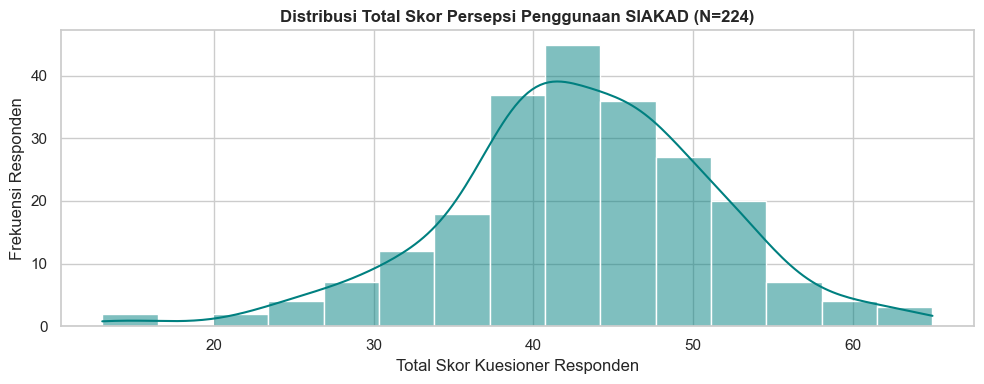

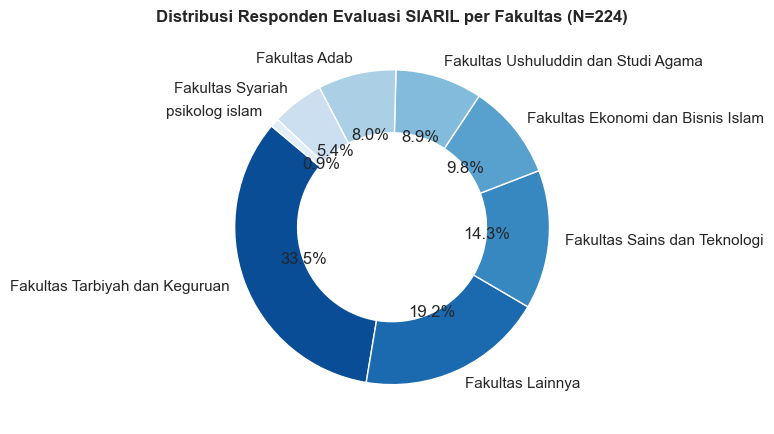

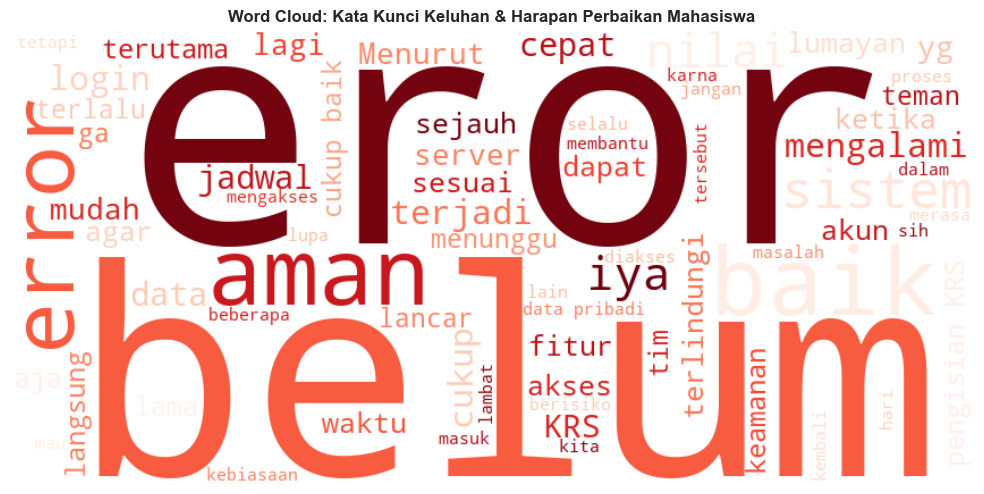

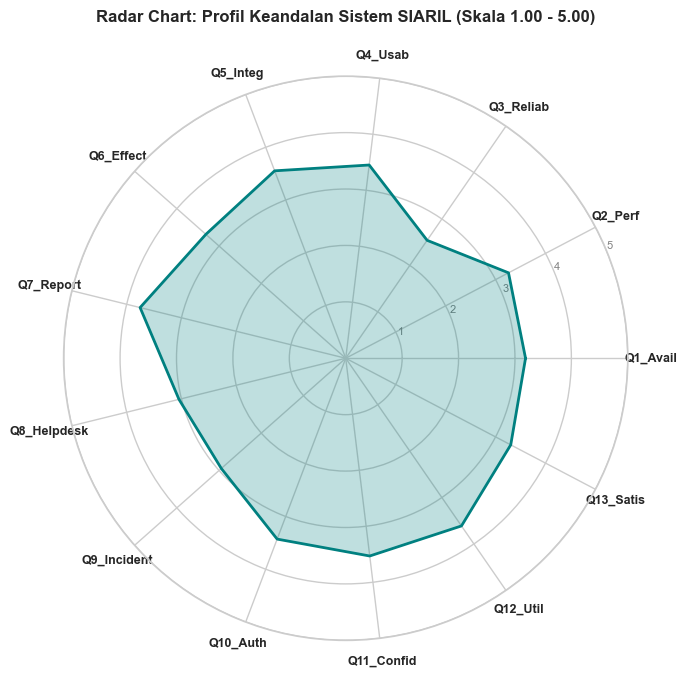

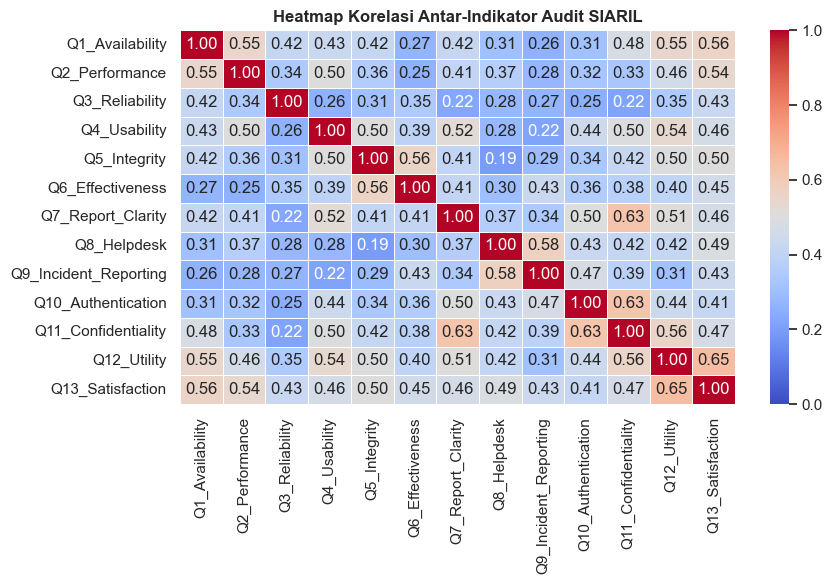

In [12]:
from wordcloud import WordCloud, STOPWORDS

print("=== TAHAP 4: EXPLORATORY DATA ANALYSIS (EDA) & VISUALISASI ===")

# 1. Tabel Statistik Deskriptif 13 Indikator Audit
eda_table = master_clean_df[likert_cols].describe().T[['mean', 'std', 'min', '50%', 'max']]
eda_table.columns = ['Rata-Rata', 'Standar Deviasi', 'Min', 'Median', 'Max']
print("\n--- TABEL STATISTIK DESKRIPTIF INDIKATOR AUDIT SIAKAD ---")
display(eda_table)

# 2. Visualisasi Grafik Distribusi Total Skor Responden
plt.figure(figsize=(10, 4))
skor_total = master_clean_df[likert_cols].sum(axis=1)
sns.histplot(skor_total, kde=True, color='teal', bins=15)
plt.title('Distribusi Total Skor Persepsi Penggunaan SIAKAD (N=224)', fontsize=12, fontweight='bold')
plt.xlabel('Total Skor Kuesioner Responden')
plt.ylabel('Frekuensi Responden')
plt.tight_layout()
plt.show()

# 3. Diagram Donut Demografi Fakultas
plt.figure(figsize=(8, 4.5))
fakultas_counts = master_clean_df['Fakultas'].value_counts()
colors = sns.color_palette('Blues_r', len(fakultas_counts))
plt.pie(fakultas_counts, labels=fakultas_counts.index, autopct='%1.1f%%', 
        startangle=140, colors=colors, wedgeprops=dict(width=0.4, edgecolor='white'))
plt.title('Distribusi Responden Evaluasi SIARIL per Fakultas (N=224)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. WordCloud Keluhan Kualitatif Mahasiswa
qual_cols = [c for c in master_clean_df.columns if c.startswith('Qual_')]
text_combined = ""
for col in qual_cols:
    text_list = master_clean_df[col].dropna().astype(str).tolist()
    text_combined += " ".join(text_list) + " "

stopwords_id = set(STOPWORDS).union({
    'yang', 'dan', 'di', 'ke', 'dari', 'ini', 'itu', 'dengan', 'untuk', 'pada', 'adalah',
    'saya', 'tidak', 'ada', 'jika', 'bila', 'karena', 'tapi', 'atau', 'akan', 'bisa', 'juga',
    'sudah', 'pernah', 'biasanya', 'kalo', 'kalau', 'saja', 'saat', 'pas', 'jadi', 'sangat',
    'terkadang', 'kadang', 'sering', 'jarang', 'paling', 'kurang', 'lebih', 'agak', 'masih',
    'selama', 'sampai', 'harus', 'banyak', 'bahkan', 'mengenai', 'terkait', 'seperti', 'mungkin',
    'tidak memberikan tanggapan', 'tanggapan', 'memberikan', 'a', 'b', '1', '2', '3', 'ya',
    'siakad', 'siaril', 'kampus', 'dosen', 'mahasiswa', 'nya'
})

wordcloud = WordCloud(width=850, height=400, background_color='white', 
                      stopwords=stopwords_id, colormap='Reds', max_words=70).generate(text_combined)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud: Kata Kunci Keluhan & Harapan Perbaikan Mahasiswa', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# 5. Radar Chart 360 Derajat
labels = ['Q1_Avail', 'Q2_Perf', 'Q3_Reliab', 'Q4_Usab', 'Q5_Integ', 'Q6_Effect', 
          'Q7_Report', 'Q8_Helpdesk', 'Q9_Incident', 'Q10_Auth', 'Q11_Confid', 'Q12_Util', 'Q13_Satis']
stats = master_clean_df[likert_cols].mean().values
angles = np.linspace(0, 2*np.pi, len(labels), endpoint=False).tolist()
stats = np.concatenate((stats, [stats[0]]))
angles += angles[:1]

fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
ax.plot(angles, stats, color='teal', linewidth=2)
ax.fill(angles, stats, color='teal', alpha=0.25)
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_yticklabels(['1', '2', '3', '4', '5'], color="grey", size=8)
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=9, fontweight='bold')
plt.title("Radar Chart: Profil Keandalan Sistem SIARIL (Skala 1.00 - 5.00)", fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# 6. Heatmap Korelasi
plt.figure(figsize=(9, 6))
sns.heatmap(master_clean_df[likert_cols].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=0, vmax=1, linewidths=0.5)
plt.title('Heatmap Korelasi Antar-Indikator Audit SIARIL', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

=== TAHAP 5: BUSINESS INTELLIGENCE (BI) ANALYST INSIGHTS ===


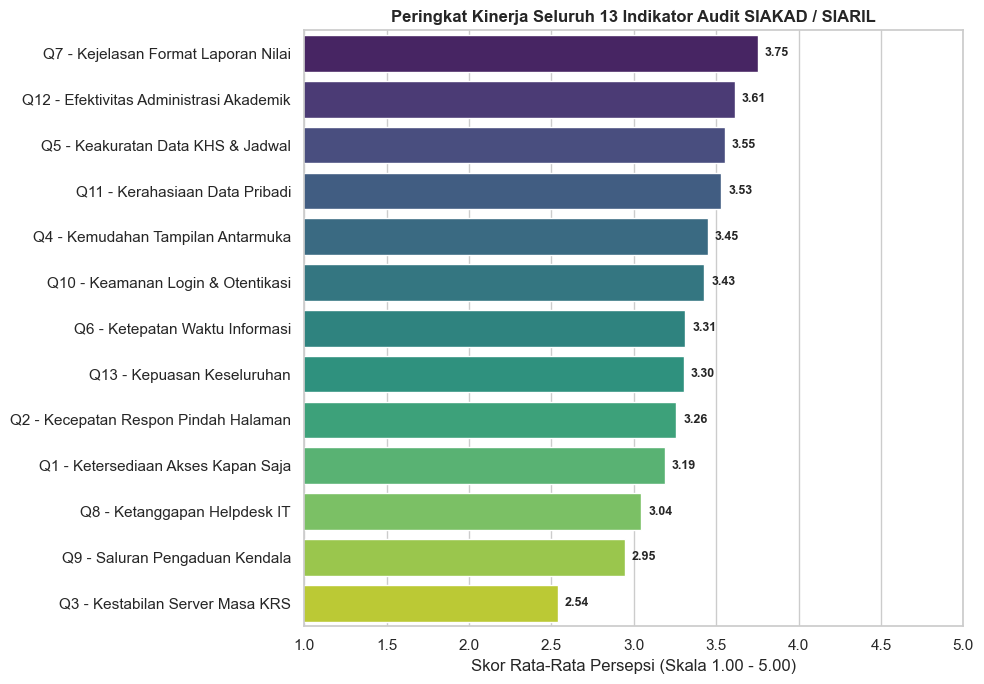

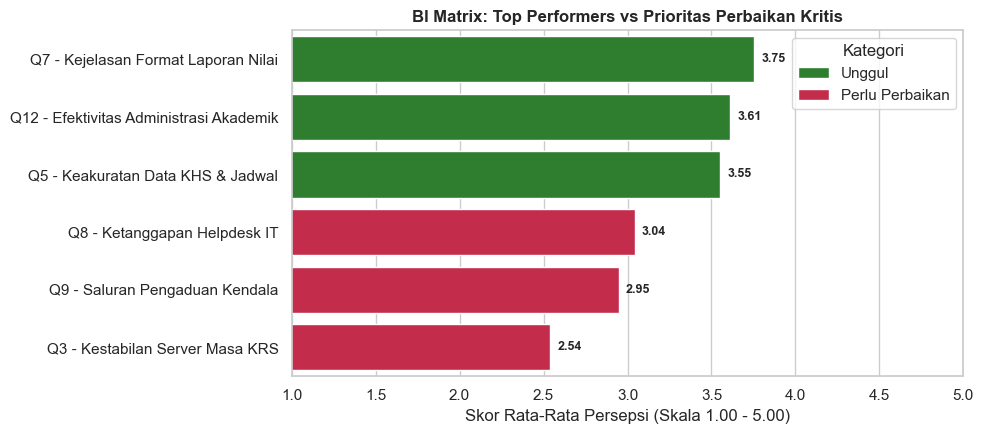

In [14]:
print("=== TAHAP 5: BUSINESS INTELLIGENCE (BI) ANALYST INSIGHTS ===")

# 1. Hitung Rata-Rata Skor dan Urutkan Seluruh 13 Indikator
avg_scores = master_clean_df[likert_cols].mean().sort_values(ascending=False)

label_map = {
    'Q7_Report_Clarity': 'Q7 - Kejelasan Format Laporan Nilai',
    'Q12_Utility': 'Q12 - Efektivitas Administrasi Akademik',
    'Q5_Integrity': 'Q5 - Keakuratan Data KHS & Jadwal',
    'Q11_Confidentiality': 'Q11 - Kerahasiaan Data Pribadi',
    'Q4_Usability': 'Q4 - Kemudahan Tampilan Antarmuka',
    'Q10_Authentication': 'Q10 - Keamanan Login & Otentikasi',
    'Q6_Effectiveness': 'Q6 - Ketepatan Waktu Informasi',
    'Q13_Satisfaction': 'Q13 - Kepuasan Keseluruhan',
    'Q2_Performance': 'Q2 - Kecepatan Respon Pindah Halaman',
    'Q1_Availability': 'Q1 - Ketersediaan Akses Kapan Saja',
    'Q8_Helpdesk': 'Q8 - Ketanggapan Helpdesk IT',
    'Q9_Incident_Reporting': 'Q9 - Saluran Pengaduan Kendala',
    'Q3_Reliability': 'Q3 - Kestabilan Server Masa KRS'
}

# A. GRAFIK BATANG SELURUH 13 INDIKATOR (FIXED)
bi_all_df = avg_scores.reset_index()
bi_all_df.columns = ['Kode', 'Skor']
bi_all_df['Indikator'] = bi_all_df['Kode'].map(label_map)

plt.figure(figsize=(10, 7))
# Perbaikan: palette='viridis' (huruf kecil) & assign hue='Indikator'
bar_all = sns.barplot(data=bi_all_df, x='Skor', y='Indikator', hue='Indikator', palette='viridis')

# Hapus legenda otomatis agar tampilan bersih
if bar_all.get_legend() is not None:
    bar_all.get_legend().remove()

plt.xlim(1, 5)
plt.title('Peringkat Kinerja Seluruh 13 Indikator Audit SIAKAD / SIARIL', fontsize=12, fontweight='bold')
plt.xlabel('Skor Rata-Rata Persepsi (Skala 1.00 - 5.00)')
plt.ylabel('')

# Label angka presisi di ujung tiap batang
for p in bar_all.patches:
    w = p.get_width()
    if w > 0:
        bar_all.annotate(f'{w:.2f}', (w, p.get_y() + p.get_height() / 2.),
                         ha='left', va='center', xytext=(5, 0),
                         textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


# B. GRAFIK BATANG MATRIKS PRIORITAS (TOP 3 VS BOTTOM 3)
top_3 = avg_scores.head(3)
bottom_3 = avg_scores.tail(3)

bi_top_bottom_df = pd.concat([top_3, bottom_3]).reset_index()
bi_top_bottom_df.columns = ['Kode', 'Skor']
bi_top_bottom_df['Indikator'] = bi_top_bottom_df['Kode'].map(label_map)
bi_top_bottom_df['Kategori'] = ['Unggul']*3 + ['Perlu Perbaikan']*3

plt.figure(figsize=(10, 4.5))
bar_tb = sns.barplot(data=bi_top_bottom_df, x='Skor', y='Indikator', hue='Kategori',
                     palette={'Unggul': 'forestgreen', 'Perlu Perbaikan': 'crimson'})
plt.xlim(1, 5)
plt.title('BI Matrix: Top Performers vs Prioritas Perbaikan Kritis', fontsize=12, fontweight='bold')
plt.xlabel('Skor Rata-Rata Persepsi (Skala 1.00 - 5.00)')
plt.ylabel('')

for p in bar_tb.patches:
    w = p.get_width()
    if w > 0:
        bar_tb.annotate(f'{w:.2f}', (w, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center', xytext=(5, 0),
                        textcoords='offset points', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()